# Group 18 - Q_learning_SARSA_Set A
## Assignment II (Set A): Robust Reinforcement Learning under Sticky Actuators
**Course:** Deep Reinforcement Learning — BITS Pilani, WILP Division
**Topic:** Tabular Q-learning (off-policy) vs SARSA (on-policy) on MountainCar-v0 with sticky actuators

### Group Contribution Declaration

| # | Name | BITS ID | Contribution |
|---|------|---------|:------------:|
| 1 | Nuzhat Fatima Khan | 2025AG05164 | 25% |
| 2 | Bhatt Ishan Bankimchandra | 2025AG05093 | 25% |
| 3 | Devansh Sadhotra | 2025AG05360 | 25% |
| 4 | Divij N. | 2025AG05352 | 25% |
| | **Total** | | **100%** |

### Contents
- **(a)** Modified environment (`gym.Wrapper`) and experimental verification
- **(b)** Tabular Q-learning — original and modified environments
- **(c)** Tabular SARSA — original and modified environments
- **(d)** Performance evaluation — five plots, greedy-policy maps, 100-episode test table
- **(e)** Discussion

All code was executed top-to-bottom in a single run; every cell's output (including the training log of every
agent) is reproduced below. Timestamps are printed at the start and end of the run and on every log line.


## 0. Setup and experimental design

One configuration block is shared by **every** experiment, so the four agents differ only in (i) the TD target and
(ii) the environment.

| Design choice | Value | Justification |
|---|---|---|
| Random seed | 18 | Same seed for all four runs (environment, exploration and tie-breaking RNGs) |
| Training episodes | 15,000 per agent | ≥ 5,000 required; MountainCar's sparse feedback means the first successes only appear once ε is fairly small, so 7,500 episodes of near-greedy training follow the decay to show converged behaviour |
| Learning rate α | 0.10 | Standard constant step size for tabular TD control; stable under the stochastic sticky transitions |
| Discount γ | 0.99 | Episodes last up to 200 steps; the goal (and +20 bonus) must stay visible over ~100–150 steps (0.99¹⁵⁰ ≈ 0.22) |
| Exploration | ε-greedy, **linear decay 1.0 → 0.01 over the first 7,500 episodes, then fixed at 0.01** | Long uniform exploration early (the Q-table is still near zero), then almost-greedy learning |
| Discretisation | **20 position × 28 velocity** uniform bins | ≥ 20×20 as required. Position width 0.09 is enough to resolve the valley and the hill. Velocity is the variable that matters for the gentle-arrival criterion, so it gets finer bins (0.005); with 28 bins the threshold **0.04 falls exactly on a bin edge**, so "v ≤ 0.04" and "v > 0.04" are never mixed inside one cell. 560 states × 3 actions keeps the table small enough to be learnt well in 15,000 episodes |
| Q-table | zeros, shape (20, 28, 3) | As specified. Since every reward is negative, zero initialisation is optimistic and drives early exploration |
| Validation set | 500 states sampled once before training (seed 18), fixed throughout | Used for the "average max_a Q" plot |


In [1]:
# ------------------------------------------------------------------
# Imports and global experiment configuration
# ------------------------------------------------------------------
%matplotlib inline
import time                                   # wall-clock timing of training runs
import datetime                               # timestamps printed in every log (virtual-lab evidence)
import platform                               # records the machine/Python version for reproducibility
import numpy as np                            # numerical arrays, Q-tables, random number generators
import gymnasium as gym                       # MountainCar-v0 environment and gym.Wrapper base class
import matplotlib                             # plotting backend configuration
import matplotlib.pyplot as plt               # all plots in part (d)
from matplotlib.colors import ListedColormap  # discrete 3-colour map for greedy-policy heatmaps
import pandas as pd                           # tabular presentation of results
from IPython.display import display, Image    # renders tables and saved figures in the notebook
import os                                     # folder for the saved figure files

FIG_DIR = "figures"                           # every plot is also saved here as a PNG
os.makedirs(FIG_DIR, exist_ok=True)


def show_fig(fig, name):
    """Save a figure to figures/<name>.png and display that PNG in the notebook.
    Displaying the saved file guarantees the plot appears even if the Jupyter
    plotting backend is not the inline one (e.g. in some virtual-lab setups)."""
    path = os.path.join(FIG_DIR, name + ".png")
    fig.savefig(path, dpi=110, bbox_inches="tight")   # write the image file
    plt.close(fig)                                    # avoid a second, backend-dependent rendering
    display(Image(filename=path))                     # embed the image in the cell output
    print("Figure saved to", path)

# Shared table style: full borders, bold shaded header, zebra rows, centred numbers
TABLE_STYLE = [
    {"selector": "", "props": "border-collapse: collapse; margin: 6px 0 12px 0; font-size: 11px;"},
    {"selector": "caption", "props": "caption-side: top; font-weight: bold; text-align: left; padding: 4px 0; font-size: 12px;"},
    {"selector": "th", "props": "border: 1px solid #555; background-color: #dde6f2; padding: 4px 8px; text-align: center; font-weight: bold;"},
    {"selector": "td", "props": "border: 1px solid #555; padding: 3px 8px; text-align: center;"},
    {"selector": "tbody tr:nth-child(even)", "props": "background-color: #f5f7fa;"},
]


def show_table(rows, columns, caption="", fmt=None):
    """Display a list of rows as a bordered HTML table (falls back to plain text outside a notebook)."""
    df = pd.DataFrame(rows, columns=columns)
    sty = df.style.set_table_styles(TABLE_STYLE).set_caption(caption).hide(axis="index")
    if fmt:                                       # optional per-column number formats, e.g. {"Rate": "{:.4f}"}
        sty = sty.format(fmt, na_rep="-")
    display(sty)                                  # nothing is returned, so the table is not shown twice

# Print a run header so every executed notebook carries a timestamp and the software versions
print("Run started at :", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Python         :", platform.python_version())
print("Gymnasium      :", gym.__version__)
print("NumPy          :", np.__version__)
print("Matplotlib     :", matplotlib.__version__)
print("Pandas         :", pd.__version__)

# Experiment-wide hyper-parameters. They are shared by ALL four agents so that the only
# differences between runs are (i) the TD target and (ii) the environment.
SEED          = 18          # single random seed used by every experiment (Group 18)
N_EPISODES    = 15000       # number of training episodes per agent (requirement: >= 5000)
ALPHA         = 0.10        # learning rate alpha
GAMMA         = 0.99        # discount factor gamma
EPS_START     = 1.00        # initial exploration rate epsilon
EPS_END       = 0.01        # final (minimum) exploration rate
EPS_DECAY_EPS = 7500        # epsilon decays LINEARLY from EPS_START to EPS_END over this many episodes, then stays at EPS_END
N_POS_BINS    = 20          # number of uniform bins for car position  in [-1.2, 0.6]  -> width 0.090
N_VEL_BINS    = 28          # number of uniform bins for car velocity  in [-0.07, 0.07] -> width 0.005
STICK_PROB    = 0.20        # probability that a CHANGED action is replaced by the previous executed action
GENTLE_VMAX   = 0.04        # velocity threshold of the gentle-arrival bonus
MA_WINDOW     = 100         # window for all moving averages in part (d)
N_VALID       = 500         # size of the fixed validation set of states used for the average max-Q plot
LOG_EVERY     = 250         # training progress is printed every LOG_EVERY episodes

print("\nConfiguration:")
for k in ["SEED", "N_EPISODES", "ALPHA", "GAMMA", "EPS_START", "EPS_END", "EPS_DECAY_EPS",
          "N_POS_BINS", "N_VEL_BINS", "STICK_PROB", "GENTLE_VMAX", "MA_WINDOW", "N_VALID"]:
    print(f"  {k:<14}= {globals()[k]}")

Run started at : 2026-11-08 17:46:10
Python         : 3.13.18
Gymnasium      : 1.4.0
NumPy          : 2.5.3
Matplotlib     : 3.11.2
Pandas         : 3.0.5

Configuration:
  SEED          = 18
  N_EPISODES    = 15000
  ALPHA         = 0.1
  GAMMA         = 0.99
  EPS_START     = 1.0
  EPS_END       = 0.01
  EPS_DECAY_EPS = 7500
  N_POS_BINS    = 20
  N_VEL_BINS    = 28
  STICK_PROB    = 0.2
  GENTLE_VMAX   = 0.04
  MA_WINDOW     = 100
  N_VALID       = 500


## (a) Modified Environment Implementation and Verification

The wrapper below implements Steps 1–6 of the specification in the stated order:

1. store the agent's action `a`;
2. sticky actuator — if `a ≠ a_prev`, draw `r ~ U[0,1)` and execute `a_prev` when `r < 0.20`; then `a_prev ← a_exec`;
3. execute `a_exec` in the original `MountainCar-v0`;
4. `R = R_base − 0.2·𝟙[a ≠ 1] + B` (penalty on the **selected** action);
5. `B = +20` only if terminated, not truncated, `x ≥ 0.5` and `v ≤ 0.04`;
6. return `obs, R, terminated, truncated, info` with the **untouched** `info` dict.

The sticky actuator has its own random-number generator (seeded through `reset(seed=…)`) so that runs are reproducible
without disturbing the base environment's RNG. A private `record` flag keeps a diagnostic log that is used **only**
in the verification cells; it is never returned to the agent.


In [2]:
# ------------------------------------------------------------------
# Part (a): Sticky-actuator MountainCar wrapper
# ------------------------------------------------------------------
class StickyActuatorMountainCar(gym.Wrapper):
    """
    gym.Wrapper around MountainCar-v0 that
      1. simulates a sticky actuator: when the agent CHANGES its action, with probability 0.20
         the previously executed action a_prev is executed instead (silently);
      2. replaces the reward with  R = R_base - 0.2 * 1[a != 1] + B,
         where a is the action SELECTED by the agent and B = +20 is the gentle-arrival bonus.
    Observation space, action space, dynamics (apart from the sticky replacement) and the
    termination / truncation conditions are inherited unchanged from the base environment.

    The optional `record` flag stores a PRIVATE diagnostic log (self._log) that is used only
    for the verification in part (a). It is never returned to the agent and never put into `info`.
    """

    def __init__(self, env, stick_prob=0.20, push_penalty=0.2, bonus=20.0, gentle_vmax=0.04,
                 record=False, rng=None):
        super().__init__(env)                      # keeps the original observation/action spaces
        self.stick_prob   = stick_prob             # probability of a stuck actuator on an action change
        self.push_penalty = push_penalty           # energy penalty for selecting a push action (0 or 2)
        self.bonus        = bonus                  # gentle-arrival bonus value B
        self.gentle_vmax  = gentle_vmax            # maximum arrival velocity that earns the bonus
        self.record       = record                 # if True, keep a private per-step diagnostic log
        self._rng         = rng if rng is not None else np.random.default_rng()  # RNG for the sticky actuator
        self.a_prev       = 1                      # action executed on the previous step (1 = do not accelerate)
        self._log         = []                     # private diagnostics (verification only)

    def reset(self, *, seed=None, options=None):
        """Reset the base env and set a_prev = 1. A seed also re-seeds the sticky-actuator RNG."""
        if seed is not None:                       # seeding makes the stuck/not-stuck draws reproducible
            self._rng = np.random.default_rng(seed + 10_000)
        self.a_prev = 1                            # specification: a_prev = 1 on every reset()
        return self.env.reset(seed=seed, options=options)   # observation and info passed through unchanged

    def step(self, action):
        """Apply Steps 1-6 of the specification, in order."""
        # Step 1: receive and store the agent's selected action (used later for the energy penalty)
        a = int(action)

        # Step 2: simulate the sticky actuator
        r_draw = None                              # random number (only drawn when the action changes)
        if a == self.a_prev:                       # same action as previously executed -> no modification
            a_exec = a
        else:                                      # action change attempted
            r_draw = self._rng.uniform(0.0, 1.0)   # r ~ U[0, 1)
            a_exec = self.a_prev if r_draw < self.stick_prob else a   # stuck -> keep a_prev
        prev_before = self.a_prev                  # kept only for the private diagnostic log
        self.a_prev = a_exec                       # update a_prev with the action ACTUALLY executed

        # Step 3: execute a_exec in the original MountainCar-v0 environment
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)

        # Step 5 (computed before Step 4 because R needs B): gentle-arrival bonus
        gentle = (terminated and not truncated
                  and obs[0] >= 0.5 and obs[1] <= self.gentle_vmax)
        B = self.bonus if gentle else 0.0

        # Step 4: modified reward; the penalty depends on the SELECTED action a, not on a_exec
        R = float(r_base) - self.push_penalty * float(a != 1) + B

        # Private diagnostics for part (a) verification (never visible to the agent)
        if self.record:
            self._log.append((prev_before, a, r_draw, a_exec, float(r_base), R, B,
                              bool(terminated), bool(truncated), float(obs[0]), float(obs[1])))

        # Step 6: return the standard 5-tuple; `info` is the untouched dict from the base env
        return obs, R, terminated, truncated, info


def make_env(modified, record=False):
    """Factory: original MountainCar-v0 (modified=False) or the sticky-actuator version (modified=True)."""
    base = gym.make("MountainCar-v0")              # includes the standard 200-step TimeLimit
    return StickyActuatorMountainCar(base, stick_prob=STICK_PROB, gentle_vmax=GENTLE_VMAX,
                                     record=record) if modified else base


# Quick structural check: the wrapper must not change the spaces
_orig, _mod = make_env(False), make_env(True)
print("Original observation space :", _orig.observation_space)
print("Modified observation space :", _mod.observation_space)
print("Original action space      :", _orig.action_space)
print("Modified action space      :", _mod.action_space)
print("Spaces identical           :", _orig.observation_space == _mod.observation_space
      and _orig.action_space == _mod.action_space)
print("Max episode steps (both)   :", _orig.spec.max_episode_steps, "/", _mod.spec.max_episode_steps)
_orig.close(); _mod.close()

Original observation space : Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Modified observation space : Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Original action space      : Discrete(3)
Modified action space      : Discrete(3)
Spaces identical           : True
Max episode steps (both)   : 200 / 200


### (a-1) Replaying the worked example from the assignment

A scripted random-number source feeds the four numbers of the specification table (0.55, 0.11, 0.74, 0.05). No number is
consumed at step 2, where the agent repeats the executed action — exactly as the specification requires.


In [3]:
# ------------------------------------------------------------------
# (a-1) Deterministic unit test: reproduce the worked example from the assignment table
# ------------------------------------------------------------------
class ScriptedRNG:
    """Stand-in RNG that returns a fixed list of 'random' numbers, so the specification example can be replayed exactly."""
    def __init__(self, values):
        self.values = list(values)                # numbers to hand out in order
    def uniform(self, low, high):
        return self.values.pop(0)                 # next scripted number (only called when the action changes)

ex_env = make_env(modified=True)                  # sticky-actuator environment
ex_env.reset(seed=SEED)                           # a_prev = 1 after reset
ex_env._rng = ScriptedRNG([0.55, 0.11, 0.74, 0.05])   # the four random numbers of the example table
ex_env.record = True                              # enable the private diagnostic log for this test

agent_actions = [2, 2, 0, 0, 1]                   # agent actions of the example (steps 1-5)
expected_exec = [2, 2, 2, 0, 0]                   # executed actions given in the example
ex_rows = []                                      # one table row per step
for t, a in enumerate(agent_actions, start=1):
    ex_env.step(a)                                # run one step of the wrapper
    prev, a_sel, r_draw, a_exec, _, R, _, _, _, _, _ = ex_env._log[-1]
    rtxt = "-" if r_draw is None else f"{r_draw:.2f}"
    ex_rows.append([t, prev, a_sel, rtxt, a_exec, expected_exec[t-1], "yes" if a_exec == expected_exec[t-1] else "NO", f"{R:+.1f}"])
show_table(ex_rows, ["Step", "a_prev", "Agent action a", "Random r", "Executed a_exec", "Expected (spec)", "Match", "Reward R"],
           "Replay of the specification example")
match = [row[3] for row in ex_env._log] == expected_exec
print("\nExecuted actions match the specification example:", match)
assert match, "Sticky-actuator logic does not reproduce the specification example"
ex_env.close()

Step,a_prev,Agent action a,Random r,Executed a_exec,Expected (spec),Match,Reward R
1,1,2,0.55,2,2,yes,-1.2
2,2,2,-,2,2,yes,-1.2
3,2,0,0.11,2,2,yes,-1.2
4,2,0,0.74,0,0,yes,-1.2
5,0,1,0.05,0,0,yes,-1.0



Executed actions match the specification example: True


### (a-2) Random-policy statistics: sticky rate, repeats, energy penalty, information leakage

300 episodes (60,000 transitions) of a uniformly random policy. The original environment is stepped in parallel with the
same actions only to compare the keys of the `info` dictionaries.


In [4]:
# ------------------------------------------------------------------
# (a-2) Random-policy verification: sticky rate, no replacement on repeats, energy penalty, info dict
# ------------------------------------------------------------------
N_VERIFY_EPISODES = 300                           # 300 episodes x 200 steps = 60,000 transitions

ver_env  = make_env(modified=True, record=True)   # modified env with private logging switched on
base_env = make_env(modified=False)               # original env, used only to compare info dictionaries
rand_rng = np.random.default_rng(SEED)            # RNG of the uniformly random policy
info_keys_mod, info_keys_base = set(), set()      # keys ever seen in the info dicts of both envs

for ep in range(N_VERIFY_EPISODES):
    _, info0 = ver_env.reset(seed=SEED + ep)      # reproducible episodes
    _, info_b = base_env.reset(seed=SEED + ep)
    info_keys_mod |= set(info0); info_keys_base |= set(info_b)
    done = False
    while not done:
        a = int(rand_rng.integers(3))             # uniformly random action
        _, _, term, trunc, info = ver_env.step(a)
        _, _, tb, trb, info_b = base_env.step(a)
        info_keys_mod |= set(info); info_keys_base |= set(info_b)
        done = term or trunc

# Convert the private log into arrays for analysis
L = ver_env._log
a_prev = np.array([x[0] for x in L]); a_sel = np.array([x[1] for x in L])
a_exec = np.array([x[3] for x in L]); r_base = np.array([x[4] for x in L])
R      = np.array([x[5] for x in L]); B      = np.array([x[6] for x in L])
drawn  = np.array([x[2] is not None for x in L])

change   = a_sel != a_prev                        # steps where the agent attempted an action change
repeat   = ~change                                # steps where the agent repeated the executed action
replaced = a_exec != a_sel                        # steps where the executed action differs from the selected one
n_ch     = change.sum(); p_hat = replaced[change].mean()
ci       = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n_ch)   # 95% normal-approximation confidence interval

print(f"Total transitions logged               : {len(L)}")
print("\n--- Sticky actuator ---")
print(f"Attempted action changes (a != a_prev) : {n_ch}")
print(f"  replaced by a_prev                   : {replaced[change].sum()}  -> rate = {p_hat:.4f}  (95% CI {p_hat-ci:.4f} - {p_hat+ci:.4f}; target 0.20)")
print(f"  every replacement used exactly a_prev: {np.all(a_exec[change & replaced] == a_prev[change & replaced])}")
print(f"Repeated actions (a == a_prev)         : {repeat.sum()}")
print(f"  replaced                             : {replaced[repeat].sum()}  (must be 0)")
print(f"  random numbers drawn on repeats      : {drawn[repeat].sum()}  (must be 0)")

# Replacement rate broken down by the attempted transition a_prev -> a
tr_rows = []                                      # replacement rate for each attempted transition a_prev -> a
for p in range(3):
    for q in range(3):
        if p != q:
            m = (a_prev == p) & (a_sel == q)
            tr_rows.append([f"{p} -> {q}", int(m.sum()), int(replaced[m].sum()), replaced[m].mean()])
tr_rows.append(["All changes", int(n_ch), int(replaced[change].sum()), p_hat])
tr_rows.append(["Repeats (a = a_prev)", int(repeat.sum()), int(replaced[repeat].sum()), replaced[repeat].mean()])
show_table(tr_rows, ["Attempted transition", "Attempts", "Replaced", "Replacement rate"],
           "Sticky-actuator replacement rate (target 0.20 for changes, 0 for repeats)", {"Replacement rate": "{:.4f}"})

# Energy penalty check: penalty = R - R_base - B must be -0.2 iff the SELECTED action is 0 or 2
penalty = np.round(R - r_base - B, 6)
push_sel = a_sel != 1
print("\n--- Energy penalty (depends on the SELECTED action) ---")
print(f"R_base values observed                 : {np.unique(r_base)}")
print(f"Selected push (0/2): penalty values    : {np.unique(penalty[push_sel])}  over {push_sel.sum()} steps")
print(f"Selected 1        : penalty values     : {np.unique(penalty[~push_sel])}  over {(~push_sel).sum()} steps")
case1 = push_sel & (a_exec == a_sel)
case2 = push_sel & (a_exec != a_sel)
case3 = (~push_sel) & (a_exec != 1)
case4 = (~push_sel) & (a_exec == 1)
show_table([["Push (0/2) selected and executed", int(case1.sum()), str(np.unique(penalty[case1])), "-0.2"],
            ["Push (0/2) selected, actuator stuck", int(case2.sum()), str(np.unique(penalty[case2])), "-0.2"],
            ["1 selected and executed", int(case4.sum()), str(np.unique(penalty[case4])), "0"],
            ["1 selected, stuck actuator kept pushing", int(case3.sum()), str(np.unique(penalty[case3])), "0"]],
           ["Case", "Steps", "Observed penalty values", "Required penalty"],
           "Energy penalty by selected vs executed action")
assert np.all(penalty[push_sel] == -0.2) and np.all(penalty[~push_sel] == 0.0)
assert replaced[repeat].sum() == 0

print("\n--- Information leakage ---")
print(f"info keys (modified) : {sorted(info_keys_mod)}")
print(f"info keys (original) : {sorted(info_keys_base)}")
print(f"Identical            : {info_keys_mod == info_keys_base}")
print(f"Random policy reached the flag in {int(np.array([x[7] for x in L]).sum())} of {N_VERIFY_EPISODES} episodes "
      f"-> bonus verified separately with hand-coded policies below.")
ver_env.close(); base_env.close()

Total transitions logged               : 60000

--- Sticky actuator ---
Attempted action changes (a != a_prev) : 39908
  replaced by a_prev                   : 7931  -> rate = 0.1987  (95% CI 0.1948 - 0.2026; target 0.20)
  every replacement used exactly a_prev: True
Repeated actions (a == a_prev)         : 20092
  replaced                             : 0  (must be 0)
  random numbers drawn on repeats      : 0  (must be 0)


Attempted transition,Attempts,Replaced,Replacement rate
0 -> 1,6575,1290,0.1962
0 -> 2,6603,1351,0.2046
1 -> 0,6658,1297,0.1948
1 -> 2,6832,1374,0.2011
2 -> 0,6595,1310,0.1986
2 -> 1,6645,1309,0.1970
All changes,39908,7931,0.1987
Repeats (a = a_prev),20092,0,0.0000



--- Energy penalty (depends on the SELECTED action) ---
R_base values observed                 : [-1.]
Selected push (0/2): penalty values    : [-0.2]  over 39997 steps
Selected 1        : penalty values     : [0.]  over 20003 steps


Case,Steps,Observed penalty values,Required penalty
Push (0/2) selected and executed,34665,[-0.2],-0.2
"Push (0/2) selected, actuator stuck",5332,[-0.2],-0.2
1 selected and executed,17404,[0.],0
"1 selected, stuck actuator kept pushing",2599,[0.],0



--- Information leakage ---
info keys (modified) : []
info keys (original) : []
Identical            : True
Random policy reached the flag in 0 of 300 episodes -> bonus verified separately with hand-coded policies below.


### (a-3) Gentle-arrival bonus

A random policy never reaches the flag, so (as permitted) hand-coded policies are used: pure energy pumping (push along
the velocity) and two "pump-then-coast" variants that stop pushing near the top. Together they produce arrivals on both
sides of the 0.04 threshold; the always-do-nothing policy provides truncated episodes.


In [5]:
# ------------------------------------------------------------------
# (a-3) Gentle-arrival bonus verification with hand-coded policies
# ------------------------------------------------------------------
def pump_policy(obs):
    """Energy pumping: always push in the direction of the current velocity (arrives fast)."""
    return 2 if obs[1] >= 0 else 0

def make_brake_policy(x_brake, v_brake):
    """Pump energy, but once past x_brake moving faster than v_brake, coast (action 1) to arrive gently."""
    def policy(obs):
        if obs[0] > x_brake and obs[1] > v_brake:
            return 1                              # stop pushing near the hill top
        return pump_policy(obs)
    return policy

policies = {"pump (push along velocity)": pump_policy,
            "brake x>0.20, v>0.030":      make_brake_policy(0.20, 0.030),
            "brake x>0.30, v>0.035":      make_brake_policy(0.30, 0.035),
            "always do-nothing (1)":      lambda obs: 1}

bonus_rows = []                                   # one row per episode: (policy, terminated, truncated, x, v, B)
for name, pol in policies.items():
    env = make_env(modified=True, record=True)
    for ep in range(100):
        obs, _ = env.reset(seed=5000 + ep)
        done = False
        while not done:
            obs, R, term, trunc, _ = env.step(pol(obs))
            done = term or trunc
        last = env._log[-1]                       # final transition of the episode
        bonus_rows.append((name, last[7], last[8], last[9], last[10], last[6]))
        env._log.clear()                          # keep memory small
    env.close()

all_ok = True
bonus_table = []                                  # one summary row per policy
for name in policies:
    rows = [r for r in bonus_rows if r[0] == name]
    flag   = [r for r in rows if r[1] and not r[2] and r[3] >= 0.5]
    gentle = [r for r in flag if r[4] <= GENTLE_VMAX]
    fast   = [r for r in flag if r[4] > GENTLE_VMAX]
    trunc  = [r for r in rows if r[2]]
    given  = [r for r in rows if r[5] == 20.0]
    # The bonus must be awarded exactly on the gentle arrivals and nowhere else
    ok = (len(given) == len(gentle)) and all(r[5] == 20.0 for r in gentle) \
         and all(r[5] == 0.0 for r in fast) and all(r[5] == 0.0 for r in trunc)
    all_ok &= ok
    mv = np.mean([r[4] for r in flag]) if flag else float("nan")
    bonus_table.append([name, len(rows), len(flag), len(gentle), len(given), len(fast), len(trunc), mv, "yes" if ok else "NO"])
show_table(bonus_table, ["Policy", "Episodes", "Reached flag", "Flag & v <= 0.04", "B = +20 given", "Flag & v > 0.04",
                         "Truncated", "Mean arrival v", "Bonus correct"],
           "Gentle-arrival bonus verification (100 episodes per policy)", {"Mean arrival v": "{:.4f}"})
print("\nBonus awarded if and only if (terminated, not truncated, x >= 0.5, v <= 0.04):", all_ok)
assert all_ok

# A few concrete arrival examples on both sides of the threshold
samples = [r for r in bonus_rows if r[1] and r[4] <= GENTLE_VMAX][:3] + [r for r in bonus_rows if r[1] and r[4] > GENTLE_VMAX][:3]
show_table([[r[0], r[3], r[4], "v <= 0.04" if r[4] <= GENTLE_VMAX else "v > 0.04", r[5]] for r in samples],
           ["Policy", "Final position x", "Final velocity v", "Speed class", "Bonus B"],
           "Sample arrivals on both sides of the threshold",
           {"Final position x": "{:.4f}", "Final velocity v": "{:.4f}", "Bonus B": "{:.0f}"})

Policy,Episodes,Reached flag,Flag & v <= 0.04,B = +20 given,Flag & v > 0.04,Truncated,Mean arrival v,Bonus correct
pump (push along velocity),100,100,32,32,68,0,0.0425,yes
"brake x>0.20, v>0.030",100,100,43,43,57,0,0.0370,yes
"brake x>0.30, v>0.035",100,100,39,39,61,0,0.0396,yes
always do-nothing (1),100,0,0,0,0,100,-,yes



Bonus awarded if and only if (terminated, not truncated, x >= 0.5, v <= 0.04): True


Policy,Final position x,Final velocity v,Speed class,Bonus B
pump (push along velocity),0.5176,0.0370,v <= 0.04,20
pump (push along velocity),0.5243,0.0262,v <= 0.04,20
pump (push along velocity),0.5145,0.0366,v <= 0.04,20
pump (push along velocity),0.5369,0.0500,v > 0.04,0
pump (push along velocity),0.5369,0.0500,v > 0.04,0
pump (push along velocity),0.5394,0.0498,v > 0.04,0


### (a-4) Visual summary of the verification

The three panels summarise the checks above: the replacement rate for every attempted transition sits on the 0.20 target while repeats are never replaced; the energy penalty follows the *selected* action only; and the +20 bonus is received exactly by the arrivals left of the v = 0.04 line.

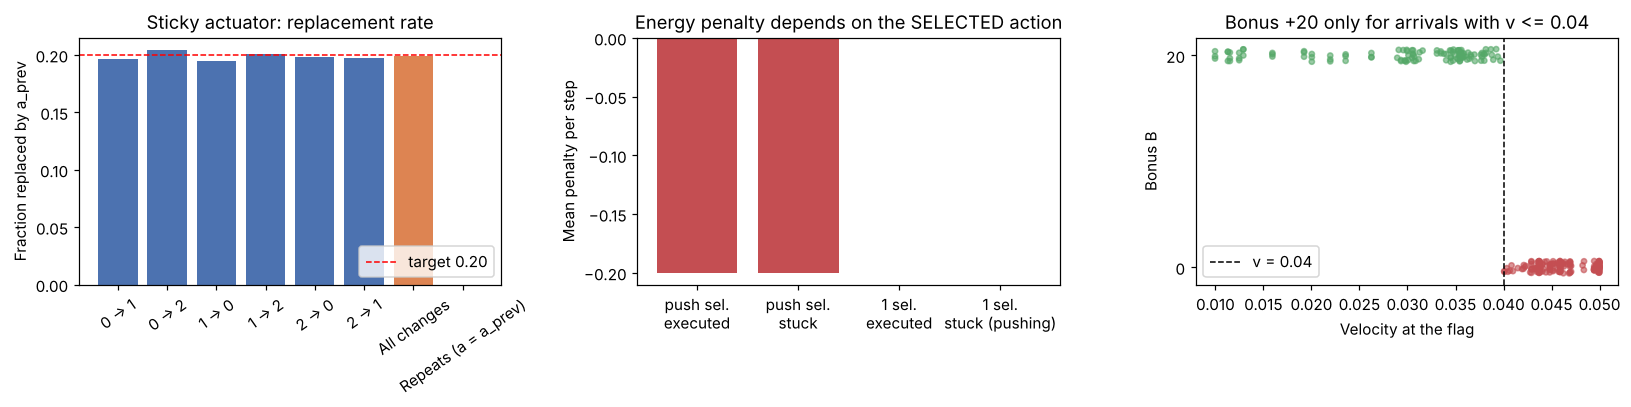

Figure saved to figures/verification_summary.png


In [6]:
# ------------------------------------------------------------------
# (a-4) Visual summary of the verification
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# Panel 1: replacement rate per attempted transition, with the 0.20 target
labels = [r[0] for r in tr_rows]                  # transition names from the table in (a-2)
rates  = [r[3] for r in tr_rows]                  # observed replacement rates
colors = ["#4c72b0"] * (len(rates) - 2) + ["#dd8452", "#55a868"]   # highlight "all changes" and "repeats"
axes[0].bar(labels, rates, color=colors)
axes[0].axhline(STICK_PROB, color="r", ls="--", lw=1, label="target 0.20")
axes[0].set_title("Sticky actuator: replacement rate"); axes[0].set_ylabel("Fraction replaced by a_prev")
axes[0].tick_params(axis="x", rotation=35); axes[0].legend()

# Panel 2: energy penalty per step, split by selected action and by whether the actuator was stuck
groups = ["push sel.\nexecuted", "push sel.\nstuck", "1 sel.\nexecuted", "1 sel.\nstuck (pushing)"]
masks  = [case1, case2, case4, case3]
axes[1].bar(groups, [penalty[m].mean() for m in masks], color=["#c44e52", "#c44e52", "#55a868", "#55a868"])
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_title("Energy penalty depends on the SELECTED action"); axes[1].set_ylabel("Mean penalty per step")

# Panel 3: final velocity of every flag arrival vs the bonus received
arr = [r for r in bonus_rows if r[1]]             # episodes that reached the flag
v_arr = np.array([r[4] for r in arr]); b_arr = np.array([r[5] for r in arr])
axes[2].scatter(v_arr, b_arr + rand_rng.uniform(-0.6, 0.6, len(b_arr)), s=12, alpha=0.6,
                c=np.where(b_arr > 0, "#55a868", "#c44e52"))   # small vertical jitter for visibility
axes[2].axvline(GENTLE_VMAX, color="k", ls="--", lw=1, label="v = 0.04")
axes[2].set_yticks([0, 20]); axes[2].set_xlabel("Velocity at the flag"); axes[2].set_ylabel("Bonus B")
axes[2].set_title("Bonus +20 only for arrivals with v <= 0.04"); axes[2].legend()
plt.tight_layout(); show_fig(fig, "verification_summary")

### Verification summary

| Requirement | Evidence above | Result |
|---|---|---|
| ≈20% of attempted changes replaced | 39,908 change attempts, rate 0.1987 (95% CI 0.195–0.203); every transition type (0→1, 0→2, …) is ≈0.20 | ✔ |
| Replacement always uses `a_prev` | checked on every replaced step | ✔ |
| No replacement when `a = a_prev` | 0 of 20,092 repeats replaced; no random number drawn on any repeat | ✔ |
| Penalty on every selected push, irrespective of execution | penalty = −0.2 on all 39,997 selected pushes, including 5,332 where the actuator was stuck | ✔ |
| No penalty when 1 is selected | penalty = 0 on all 20,003 selections of 1, including 2,599 where the stuck actuator kept pushing | ✔ |
| +20 only on gentle arrival | bonus given on exactly the arrivals with v ≤ 0.04; never on fast arrivals (v ≈ 0.05) or truncations | ✔ |
| Spaces / termination unchanged; nothing leaked in `info` | identical spaces, 200-step limit, identical (empty) `info` | ✔ |
| Worked example reproduced | executed actions 2, 2, 2, 0, 0 | ✔ |


## (b) Q-Learning  and  (c) SARSA — shared implementation

Both agents use **one** function, `train_agent`, so that everything except the TD target is literally the same code:
discretisation, zero-initialised Q-table, ε-greedy behaviour policy, seed, RNG call order, α, γ and number of episodes.

* **Q-learning (off-policy):** `Q(s,a) ← Q(s,a) + α [R + γ·max_a′ Q(s′,a′) − Q(s,a)]`
* **SARSA (on-policy):** `Q(s,a) ← Q(s,a) + α [R + γ·Q(s′,a′) − Q(s,a)]`, with `a′` the action the ε-greedy policy actually takes next.

Implementation details that follow the specification:
* `a` in the update is the action **selected** by the agent (the executed action is hidden).
* If `terminated`, the target is just `R` (no bootstrapping). **Truncation at 200 steps is not terminal**, so we still bootstrap from `s′`.
* In both algorithms `a′` is drawn before the update; Q-learning ignores it in the target but still executes it — so both
  agents consume random numbers in exactly the same order and the TD target really is the only difference.
* Ties in `argmax` are broken uniformly at random (essential with a zero-initialised table).

The training log prints, every 250 episodes, ε, the episode reward, 100-episode moving averages of reward, success,
gentle-arrival and push counts, and the average max-Q on the validation set.


In [7]:
# ------------------------------------------------------------------
# Parts (b) and (c): shared tabular machinery for Q-learning and SARSA
# ------------------------------------------------------------------
POS_LOW,  POS_HIGH = -1.2, 0.6                 # position range of MountainCar-v0
VEL_LOW,  VEL_HIGH = -0.07, 0.07               # velocity range of MountainCar-v0
POS_EDGES = np.linspace(POS_LOW, POS_HIGH, N_POS_BINS + 1)[1:-1]   # interior bin edges (uniform)
VEL_EDGES = np.linspace(VEL_LOW, VEL_HIGH, N_VEL_BINS + 1)[1:-1]   # interior bin edges (uniform)


def discretize(obs):
    """Map a continuous observation (position, velocity) to integer bin indices (i_pos, i_vel)."""
    i_pos = int(np.digitize(obs[0], POS_EDGES))   # 0 .. N_POS_BINS-1
    i_vel = int(np.digitize(obs[1], VEL_EDGES))   # 0 .. N_VEL_BINS-1
    return i_pos, i_vel


def epsilon_at(episode):
    """Linear epsilon schedule: EPS_START -> EPS_END over EPS_DECAY_EPS episodes, then constant."""
    frac = min(1.0, episode / EPS_DECAY_EPS)       # fraction of the decay period already elapsed
    return EPS_START + frac * (EPS_END - EPS_START)


def greedy_action(q_row, rng):
    """Greedy action for one state's Q-values; ties broken uniformly at random (important with zero init)."""
    best = np.flatnonzero(q_row == q_row.max())   # all actions that share the maximum value
    return int(rng.choice(best))


def epsilon_greedy(Q, s, eps, rng):
    """epsilon-greedy behaviour policy used by BOTH algorithms."""
    if rng.random() < eps:                        # explore with probability epsilon
        return int(rng.integers(3))
    return greedy_action(Q[s], rng)               # exploit otherwise


def make_validation_states(n, seed):
    """Fixed validation set: n states sampled ONCE (uniformly over the state box) before any training."""
    rng = np.random.default_rng(seed)
    pos = rng.uniform(POS_LOW, 0.5, n)            # positions before the flag (non-terminal states)
    vel = rng.uniform(VEL_LOW, VEL_HIGH, n)
    idx = np.array([discretize((p, v)) for p, v in zip(pos, vel)])   # pre-computed bin indices
    return np.column_stack([pos, vel]), idx


VALID_STATES, VALID_IDX = make_validation_states(N_VALID, SEED)
print(f"Position bin width = {(POS_HIGH-POS_LOW)/N_POS_BINS:.4f}, velocity bin width = {(VEL_HIGH-VEL_LOW)/N_VEL_BINS:.4f}")
print(f"Velocity 0.04 lies exactly on a bin edge: {np.any(np.isclose(VEL_EDGES, GENTLE_VMAX))}")
print(f"Q-table shape = ({N_POS_BINS}, {N_VEL_BINS}, 3) = {N_POS_BINS*N_VEL_BINS*3} entries")
print("Validation set:", VALID_STATES.shape[0], "states; first 3 =", np.round(VALID_STATES[:3], 4).tolist())
print("epsilon at episodes 0, 2500, 5000, 7500, 15000:",
      [round(epsilon_at(e), 4) for e in (0, 2500, 5000, 7500, 15000)])


def train_agent(algo, modified, n_episodes=N_EPISODES, seed=SEED, verbose=True):
    """
    Train one tabular agent.
      algo     : 'qlearning' (off-policy target max_a' Q(s',a'))  or  'sarsa' (on-policy target Q(s',a'))
      modified : True -> sticky-actuator MountainCar, False -> original MountainCar-v0
    Everything except the TD target is IDENTICAL for the two algorithms: the same loop, the same
    behaviour policy, the same RNG streams and the same order of random draws. In both cases the next
    action a' is drawn from the epsilon-greedy policy at s' before the update; Q-learning simply ignores
    it in its target, SARSA uses it.
    Returns the final Q-table and a dict of per-episode training statistics.
    """
    env = make_env(modified)                         # fresh environment instance
    rng = np.random.default_rng(seed)                # agent RNG (exploration + tie-breaking)
    env.action_space.seed(seed)                      # not used by the agent, seeded for completeness
    Q = np.zeros((N_POS_BINS, N_VEL_BINS, 3))        # Q-table initialised to zero

    # Per-episode statistics collected for part (d)
    stats = {k: np.zeros(n_episodes) for k in
             ["reward", "length", "success", "gentle", "pushes", "arrival_vel", "avg_maxq", "epsilon"]}
    t0 = time.time()

    for ep in range(n_episodes):
        eps = epsilon_at(ep)                         # exploration rate for this episode
        obs, _ = env.reset(seed=seed if ep == 0 else None)   # seed only the first reset (then the env RNG continues)
        s = discretize(obs)                          # discrete current state
        a = epsilon_greedy(Q, s, eps, rng)           # first action
        ep_reward, pushes, steps = 0.0, 0, 0
        terminated = truncated = False

        while not (terminated or truncated):
            pushes += int(a != 1)                    # count SELECTED push actions (0 or 2)
            obs2, R, terminated, truncated, _ = env.step(a)   # executed action is hidden from the agent
            s2 = discretize(obs2)
            a2 = epsilon_greedy(Q, s2, eps, rng)     # next action from the behaviour policy

            # ---------------- TD target: the ONLY algorithm-specific line ----------------
            if terminated:                           # true terminal state: no bootstrapping
                target = R
            elif algo == "qlearning":                # off-policy: greedy value of s'
                target = R + GAMMA * Q[s2].max()
            else:                                    # SARSA, on-policy: value of the action actually chosen
                target = R + GAMMA * Q[s2][a2]
            # (truncation at 200 steps is NOT terminal, so we still bootstrap from s')
            # ------------------------------------------------------------------------------

            Q[s][a] += ALPHA * (target - Q[s][a])    # TD update for the SELECTED action a
            ep_reward += R
            steps += 1
            s, a = s2, a2                            # move to the next state-action pair

        # Episode-level statistics
        stats["reward"][ep]      = ep_reward
        stats["length"][ep]      = steps
        stats["success"][ep]     = float(terminated)                         # reached the flag
        stats["gentle"][ep]      = float(terminated and not truncated and obs2[1] <= GENTLE_VMAX)
        stats["pushes"][ep]      = pushes
        stats["arrival_vel"][ep] = obs2[1] if terminated else np.nan
        stats["avg_maxq"][ep]    = Q[VALID_IDX[:, 0], VALID_IDX[:, 1]].max(axis=1).mean()  # fixed validation set
        stats["epsilon"][ep]     = eps

        if verbose and ((ep + 1) % LOG_EVERY == 0 or ep == 0):
            lo = max(0, ep + 1 - MA_WINDOW)
            print(f"[{datetime.datetime.now():%H:%M:%S}] ep {ep+1:5d} | eps {eps:.3f} | "
                  f"R {ep_reward:8.2f} | MA100 R {stats['reward'][lo:ep+1].mean():8.2f} | "
                  f"succ {stats['success'][lo:ep+1].mean():.2f} | gentle {stats['gentle'][lo:ep+1].mean():.2f} | "
                  f"push {stats['pushes'][lo:ep+1].mean():6.1f} | avg maxQ {stats['avg_maxq'][ep]:8.2f}")
    env.close()
    if verbose:
        print(f"Finished {n_episodes} episodes in {time.time()-t0:.1f} s")
    return Q, stats

Position bin width = 0.0900, velocity bin width = 0.0050
Velocity 0.04 lies exactly on a bin edge: True
Q-table shape = (20, 28, 3) = 1680 entries
Validation set: 500 states; first 3 = [[-0.5212, 0.0559], [0.0196, -0.0354], [-0.7226, 0.0596]]
epsilon at episodes 0, 2500, 5000, 7500, 15000: [1.0, 0.67, 0.34, 0.01, 0.01]


In [8]:
RESULTS = {}   # dictionary that collects (Q-table, training statistics) of the four agents

### (b-1) Q-learning — Original MountainCar-v0

In [9]:
# ------------------------------------------------------------------
# Training loop driver: qlearning on the ORIGINAL environment
# ------------------------------------------------------------------
print(f"=== Q-learning - Original env | seed={SEED}, alpha={ALPHA}, gamma={GAMMA}, bins={N_POS_BINS}x{N_VEL_BINS}, episodes={N_EPISODES} ===")
Q_q_orig, S_q_orig = train_agent("qlearning", modified=False)   # identical settings for all four runs
RESULTS["q_orig"] = (Q_q_orig, S_q_orig)                           # stored for part (d)

=== Q-learning - Original env | seed=18, alpha=0.1, gamma=0.99, bins=20x28, episodes=15000 ===
[17:46:12] ep     1 | eps 1.000 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  137.0 | avg maxQ    -0.01


[17:46:12] ep   250 | eps 0.967 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  134.6 | avg maxQ    -0.66


[17:46:13] ep   500 | eps 0.934 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  135.4 | avg maxQ    -0.95


[17:46:14] ep   750 | eps 0.901 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  137.2 | avg maxQ    -1.25


[17:46:14] ep  1000 | eps 0.868 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  137.8 | avg maxQ    -1.65


[17:46:15] ep  1250 | eps 0.835 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  137.7 | avg maxQ    -1.97


... (51 outputs left out)

[17:46:59] ep 14250 | eps 0.010 | R  -146.00 | MA100 R  -162.63 | succ 0.95 | gentle 0.85 | push  134.6 | avg maxQ   -32.26


[17:47:00] ep 14500 | eps 0.010 | R  -149.00 | MA100 R  -142.89 | succ 0.99 | gentle 0.91 | push  112.1 | avg maxQ   -32.15


[17:47:01] ep 14750 | eps 0.010 | R  -143.00 | MA100 R  -142.80 | succ 0.99 | gentle 0.98 | push  113.5 | avg maxQ   -31.96


[17:47:01] ep 15000 | eps 0.010 | R  -114.00 | MA100 R  -136.30 | succ 1.00 | gentle 0.72 | push  113.0 | avg maxQ   -31.64
Finished 15000 episodes in 49.8 s


### (b-2) Q-learning — Modified (sticky-actuator) MountainCar-v0

In [10]:
# ------------------------------------------------------------------
# Training loop driver: qlearning on the MODIFIED environment
# ------------------------------------------------------------------
print(f"=== Q-learning - Modified env | seed={SEED}, alpha={ALPHA}, gamma={GAMMA}, bins={N_POS_BINS}x{N_VEL_BINS}, episodes={N_EPISODES} ===")
Q_q_mod, S_q_mod = train_agent("qlearning", modified=True)   # identical settings for all four runs
RESULTS["q_mod"] = (Q_q_mod, S_q_mod)                           # stored for part (d)

=== Q-learning - Modified env | seed=18, alpha=0.1, gamma=0.99, bins=20x28, episodes=15000 ===
[17:47:01] ep     1 | eps 1.000 | R  -227.40 | MA100 R  -227.40 | succ 0.00 | gentle 0.00 | push  137.0 | avg maxQ    -0.00


[17:47:02] ep   250 | eps 0.967 | R  -227.80 | MA100 R  -226.77 | succ 0.00 | gentle 0.00 | push  133.9 | avg maxQ    -0.97


[17:47:03] ep   500 | eps 0.934 | R  -227.80 | MA100 R  -226.73 | succ 0.00 | gentle 0.00 | push  133.7 | avg maxQ    -1.44


[17:47:04] ep   750 | eps 0.901 | R  -226.60 | MA100 R  -226.99 | succ 0.00 | gentle 0.00 | push  134.9 | avg maxQ    -1.90


[17:47:04] ep  1000 | eps 0.868 | R  -226.60 | MA100 R  -227.00 | succ 0.00 | gentle 0.00 | push  135.0 | avg maxQ    -2.39


[17:47:05] ep  1250 | eps 0.835 | R  -224.40 | MA100 R  -226.79 | succ 0.00 | gentle 0.00 | push  133.9 | avg maxQ    -2.91


... (51 outputs left out)

[17:47:53] ep 14250 | eps 0.010 | R  -155.40 | MA100 R  -165.75 | succ 0.93 | gentle 0.93 | push  116.3 | avg maxQ   -28.45


[17:47:54] ep 14500 | eps 0.010 | R  -159.40 | MA100 R  -157.93 | succ 0.98 | gentle 0.98 | push  103.8 | avg maxQ   -28.93


[17:47:55] ep 14750 | eps 0.010 | R  -148.80 | MA100 R  -166.23 | succ 0.99 | gentle 0.99 | push  109.8 | avg maxQ   -29.08


[17:47:56] ep 15000 | eps 0.010 | R  -194.00 | MA100 R  -172.24 | succ 0.98 | gentle 0.97 | push  105.7 | avg maxQ   -29.29
Finished 15000 episodes in 54.5 s


## (c) SARSA

Same discretisation, Q-table initialisation, α, γ, exploration schedule, seed and number of episodes as part (b) — the
`train_agent` function is called with `algo="sarsa"`, which switches only the TD target line.

### (c-1) SARSA — Original MountainCar-v0

In [11]:
# ------------------------------------------------------------------
# Training loop driver: sarsa on the ORIGINAL environment
# ------------------------------------------------------------------
print(f"=== SARSA - Original env | seed={SEED}, alpha={ALPHA}, gamma={GAMMA}, bins={N_POS_BINS}x{N_VEL_BINS}, episodes={N_EPISODES} ===")
Q_s_orig, S_s_orig = train_agent("sarsa", modified=False)   # identical settings for all four runs
RESULTS["s_orig"] = (Q_s_orig, S_s_orig)                           # stored for part (d)

=== SARSA - Original env | seed=18, alpha=0.1, gamma=0.99, bins=20x28, episodes=15000 ===
[17:47:56] ep     1 | eps 1.000 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  137.0 | avg maxQ    -0.01


[17:47:56] ep   250 | eps 0.967 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  134.1 | avg maxQ    -1.51


[17:47:57] ep   500 | eps 0.934 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  135.2 | avg maxQ    -2.44


[17:47:58] ep   750 | eps 0.901 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  136.7 | avg maxQ    -3.19


[17:47:59] ep  1000 | eps 0.868 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  138.0 | avg maxQ    -4.05


[17:47:59] ep  1250 | eps 0.835 | R  -200.00 | MA100 R  -200.00 | succ 0.00 | gentle 0.00 | push  138.6 | avg maxQ    -4.86


... (51 outputs left out)

[17:48:38] ep 14250 | eps 0.010 | R  -148.00 | MA100 R  -152.70 | succ 0.99 | gentle 0.99 | push  123.4 | avg maxQ   -31.10


[17:48:39] ep 14500 | eps 0.010 | R  -147.00 | MA100 R  -154.37 | succ 0.95 | gentle 0.95 | push  125.4 | avg maxQ   -31.15


[17:48:40] ep 14750 | eps 0.010 | R  -146.00 | MA100 R  -145.01 | succ 1.00 | gentle 1.00 | push  115.6 | avg maxQ   -30.86


[17:48:40] ep 15000 | eps 0.010 | R  -123.00 | MA100 R  -164.76 | succ 0.97 | gentle 0.97 | push  137.5 | avg maxQ   -31.20
Finished 15000 episodes in 44.6 s


### (c-2) SARSA — Modified (sticky-actuator) MountainCar-v0

In [12]:
# ------------------------------------------------------------------
# Training loop driver: sarsa on the MODIFIED environment
# ------------------------------------------------------------------
print(f"=== SARSA - Modified env | seed={SEED}, alpha={ALPHA}, gamma={GAMMA}, bins={N_POS_BINS}x{N_VEL_BINS}, episodes={N_EPISODES} ===")
Q_s_mod, S_s_mod = train_agent("sarsa", modified=True)   # identical settings for all four runs
RESULTS["s_mod"] = (Q_s_mod, S_s_mod)                           # stored for part (d)

=== SARSA - Modified env | seed=18, alpha=0.1, gamma=0.99, bins=20x28, episodes=15000 ===
[17:48:40] ep     1 | eps 1.000 | R  -227.40 | MA100 R  -227.40 | succ 0.00 | gentle 0.00 | push  137.0 | avg maxQ    -0.00


[17:48:41] ep   250 | eps 0.967 | R  -227.60 | MA100 R  -226.72 | succ 0.00 | gentle 0.00 | push  133.6 | avg maxQ    -1.77


[17:48:42] ep   500 | eps 0.934 | R  -228.60 | MA100 R  -226.79 | succ 0.00 | gentle 0.00 | push  134.0 | avg maxQ    -2.93


[17:48:43] ep   750 | eps 0.901 | R  -225.80 | MA100 R  -226.85 | succ 0.00 | gentle 0.00 | push  134.2 | avg maxQ    -3.82


[17:48:43] ep  1000 | eps 0.868 | R  -226.40 | MA100 R  -227.11 | succ 0.00 | gentle 0.00 | push  135.6 | avg maxQ    -4.85


[17:48:44] ep  1250 | eps 0.835 | R  -224.60 | MA100 R  -226.71 | succ 0.00 | gentle 0.00 | push  133.5 | avg maxQ    -5.74


... (51 outputs left out)

[17:49:30] ep 14250 | eps 0.010 | R  -151.80 | MA100 R  -148.65 | succ 1.00 | gentle 1.00 | push   98.6 | avg maxQ   -29.44


[17:49:31] ep 14500 | eps 0.010 | R  -152.00 | MA100 R  -148.18 | succ 0.98 | gentle 0.97 | push  101.0 | avg maxQ   -29.55


[17:49:32] ep 14750 | eps 0.010 | R  -149.80 | MA100 R  -147.70 | succ 1.00 | gentle 0.99 | push   99.9 | avg maxQ   -29.51


[17:49:33] ep 15000 | eps 0.010 | R  -119.60 | MA100 R  -146.87 | succ 1.00 | gentle 1.00 | push   99.1 | avg maxQ   -29.41
Finished 15000 episodes in 52.3 s


## (d) Performance Evaluation

Colour encodes the algorithm (blue = Q-learning, orange = SARSA); line style encodes the environment (solid = original,
dashed = modified). The dotted vertical line marks episode 7,500, where ε reaches its floor of 0.01.

**Note on scales:** the original environment pays −1 per step, the modified one −1, an extra −0.2 per selected push and
+20 for a gentle arrival, so rewards and Q-values are compared *within* an environment; across environments we compare
shapes, rates and behaviour.

### Plot 1 — Episode reward (100-episode moving average)


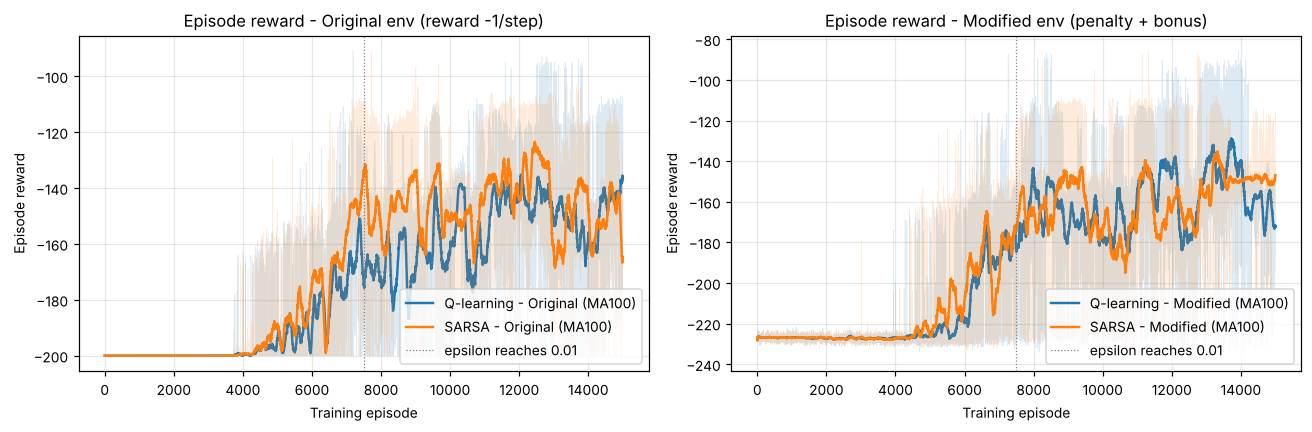

Figure saved to figures/plot1_episode_reward.png


In [13]:
# ------------------------------------------------------------------
# Part (d): plotting helpers and shared plot styling
# ------------------------------------------------------------------
AGENTS = {                                        # key -> (label, colour, line style)
    "q_orig":  ("Q-learning - Original", "#1f77b4", "-"),
    "s_orig":  ("SARSA - Original",      "#ff7f0e", "-"),
    "q_mod":   ("Q-learning - Modified", "#1f77b4", "--"),
    "s_mod":   ("SARSA - Modified",      "#ff7f0e", "--"),
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


def moving_average(x, w=MA_WINDOW):
    """Trailing moving average over the previous w episodes (shorter window for the first w-1 episodes)."""
    x = np.asarray(x, dtype=float)
    c = np.cumsum(np.insert(x, 0, 0.0))           # prefix sums for O(n) averaging
    n = np.arange(1, len(x) + 1)
    lo = np.maximum(0, n - w)                     # start index of each window
    return (c[n] - c[lo]) / (n - lo)


def plot_metric(ax, key_stat, title, ylabel, smooth=True, raw_alpha=0.0):
    """Draw one statistic for all four agents on a given axis."""
    for k, (lab, col, ls) in AGENTS.items():
        y = RESULTS[k][1][key_stat]
        if raw_alpha > 0:                         # optionally show the unsmoothed signal faintly
            ax.plot(y, color=col, alpha=raw_alpha, lw=0.4)
        ax.plot(moving_average(y) if smooth else y, color=col, ls=ls, lw=1.4, label=lab)
    ax.axvline(EPS_DECAY_EPS, color="grey", lw=0.8, ls=":")   # end of epsilon decay
    ax.set_title(title); ax.set_xlabel("Training episode"); ax.set_ylabel(ylabel)


# Plot 1: episode reward vs training episode (100-episode moving average)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, keys, ttl in zip(axes, [("q_orig", "s_orig"), ("q_mod", "s_mod")],
                         ["Original env (reward -1/step)", "Modified env (penalty + bonus)"]):
    for k in keys:
        lab, col, ls = AGENTS[k]
        ax.plot(RESULTS[k][1]["reward"], color=col, alpha=0.15, lw=0.4)
        ax.plot(moving_average(RESULTS[k][1]["reward"]), color=col, lw=1.6, label=lab + " (MA100)")
    ax.axvline(EPS_DECAY_EPS, color="grey", lw=0.8, ls=":", label="epsilon reaches 0.01")
    ax.set_title("Episode reward - " + ttl); ax.set_xlabel("Training episode"); ax.set_ylabel("Episode reward")
    ax.legend(loc="lower right")
plt.tight_layout(); show_fig(fig, "plot1_episode_reward")

**Interpretation — episode reward.** For the first ~3,500 episodes ε is large and no agent reaches the flag: the reward is
flat at −200 (original) or ≈ −227 (modified: −200 plus ≈ 136 selected pushes × −0.2). Learning takes off between
episodes 4,000 and 7,500 as ε falls, and all four curves plateau after ε reaches 0.01.
* *Q-learning vs SARSA:* in both environments SARSA's curve rises slightly earlier during the decay phase, because SARSA
  learns the value of the ε-greedy policy it is actually following and therefore avoids actions that only look good when
  followed by perfect greedy play. After convergence the two curves overlap within their noise band.
* *Original vs modified:* the modified curves start ~27 lower (energy penalty) and end in a similar −140 to −175 band,
  even though modified episodes earn +20 on most arrivals — the agents use fewer pushes but take longer to reach the
  flag. The modified curves are also more jagged: the sticky actuator makes returns from the same state random.


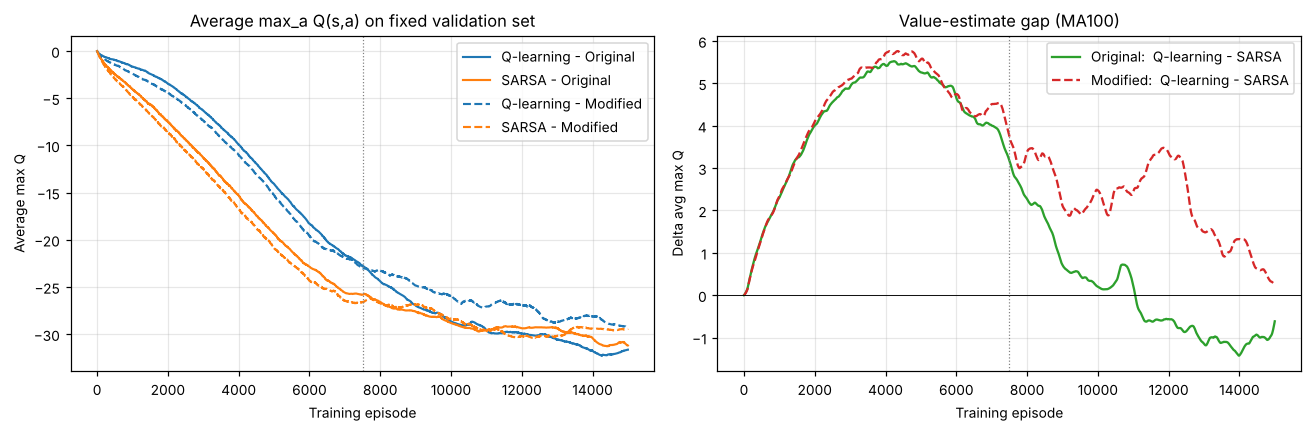

Figure saved to figures/plot2_avg_max_q.png


Environment,Mean gap (Q-learning - SARSA),Mean |gap|,Std of gap
Original,+0.029,0.967,1.160
Modified,+2.215,2.215,0.923


Agent,Final average max Q
Q-learning - Original,-31.642
SARSA - Original,-31.204
Q-learning - Modified,-29.289
SARSA - Modified,-29.408


In [14]:
# Plot 2: average predicted value  mean_s max_a Q(s,a)  on the FIXED validation set
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_metric(axes[0], "avg_maxq", "Average max_a Q(s,a) on fixed validation set", "Average max Q", smooth=False)
axes[0].legend()
# Right panel: value gap between Q-learning and SARSA in each environment
gap_orig = RESULTS["q_orig"][1]["avg_maxq"] - RESULTS["s_orig"][1]["avg_maxq"]
gap_mod  = RESULTS["q_mod"][1]["avg_maxq"]  - RESULTS["s_mod"][1]["avg_maxq"]
axes[1].plot(moving_average(gap_orig), label="Original:  Q-learning - SARSA", color="#2ca02c")
axes[1].plot(moving_average(gap_mod),  label="Modified:  Q-learning - SARSA", color="#d62728", ls="--")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].axvline(EPS_DECAY_EPS, color="grey", lw=0.8, ls=":")
axes[1].set_title("Value-estimate gap (MA100)"); axes[1].set_xlabel("Training episode"); axes[1].set_ylabel("Delta avg max Q")
axes[1].legend()
plt.tight_layout(); show_fig(fig, "plot2_avg_max_q")

# Numeric summary of the gap (mean over the converged phase, after epsilon reached its floor)
late = slice(EPS_DECAY_EPS, N_EPISODES)
show_table([[name, g[late].mean(), np.abs(g[late]).mean(), g[late].std()] for name, g in [("Original", gap_orig), ("Modified", gap_mod)]],
           ["Environment", "Mean gap (Q-learning - SARSA)", "Mean |gap|", "Std of gap"],
           f"Value-estimate gap, episodes {EPS_DECAY_EPS}-{N_EPISODES} (after epsilon reached 0.01)",
           {"Mean gap (Q-learning - SARSA)": "{:+.3f}", "Mean |gap|": "{:.3f}", "Std of gap": "{:.3f}"})
show_table([[lab, RESULTS[k][1]["avg_maxq"][-1]] for k, (lab, _, _) in AGENTS.items()],
           ["Agent", "Final average max Q"], "Final value estimates on the validation set", {"Final average max Q": "{:.3f}"})

**Interpretation — average predicted value.** All curves start at 0 (zero initialisation) and fall as the negative
step rewards are propagated back; they flatten after ε reaches its floor.
* *Early phase (ε large):* SARSA's values are clearly lower than Q-learning's in **both** environments (gap up to ≈ +5.5).
  SARSA evaluates the exploratory policy, whose random actions waste time; Q-learning's `max` target evaluates the
  greedy policy and ignores exploration — the textbook on-/off-policy difference.
* *Converged phase (episodes 7,500–15,000):* in the **original** environment the gap collapses to essentially zero
  (mean +0.03, it even changes sign), because with ε = 0.01 the behaviour and greedy policies nearly coincide.
  In the **modified** environment the gap stays positive throughout (mean **+2.2**, never crossing zero in the MA100 curve):
  Q-learning keeps valuing states higher than SARSA. Its `max` target assumes the chosen action is executed and is then
  followed by optimal actions, but under sticky actuators 20% of action changes do not happen, so the next value it
  bootstraps from is systematically too optimistic. SARSA bootstraps from the action actually taken next and thereby
  absorbs more of this execution noise.


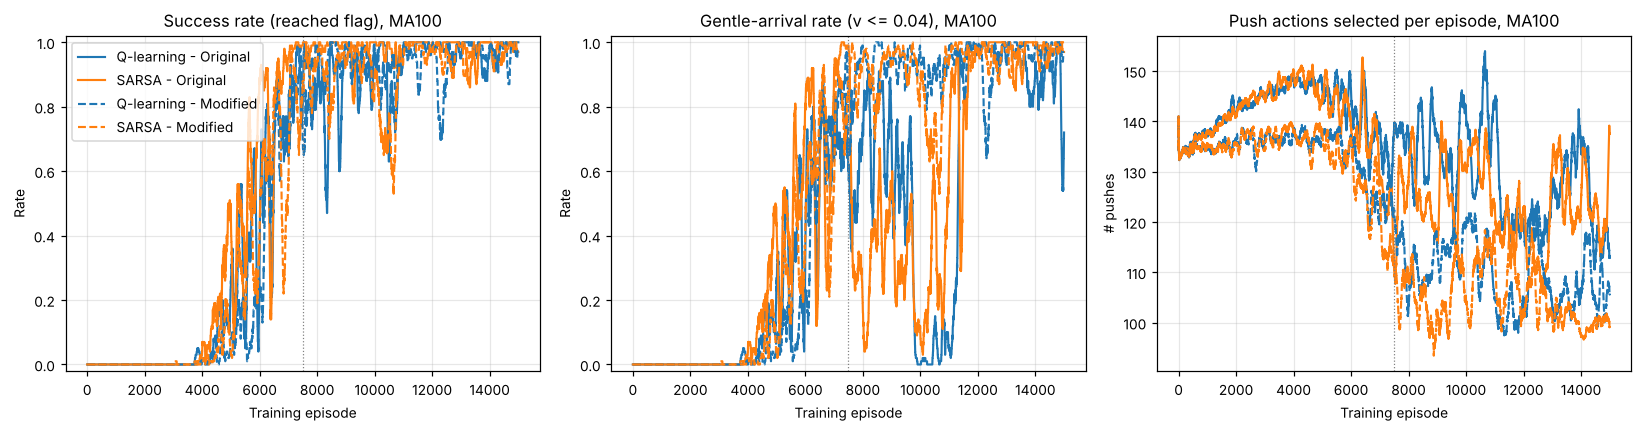

Figure saved to figures/plot3_4_success_gentle_pushes.png


Agent,Success rate,Gentle rate,Gentle / success,Mean arrival v,Pushes / episode,Push fraction
Q-learning - Original,0.933,0.667,0.715,0.0333,129.1,0.836
SARSA - Original,0.980,0.651,0.664,0.0338,124.1,0.853
Q-learning - Modified,0.942,0.939,0.997,0.0247,109.6,0.703
SARSA - Modified,0.933,0.928,0.995,0.0276,104.9,0.669


In [15]:
# Plot 3: success rate and gentle-arrival rate (MA over previous 100 episodes)
# Plot 4: average number of SELECTED push actions (0 or 2) per episode
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_metric(axes[0], "success", "Success rate (reached flag), MA100", "Rate")
plot_metric(axes[1], "gentle",  "Gentle-arrival rate (v <= 0.04), MA100", "Rate")
plot_metric(axes[2], "pushes",  "Push actions selected per episode, MA100", "# pushes")
axes[0].legend(loc="upper left"); axes[0].set_ylim(-0.02, 1.02); axes[1].set_ylim(-0.02, 1.02)
plt.tight_layout(); show_fig(fig, "plot3_4_success_gentle_pushes")

# Arrival-speed statistics during training (only successful episodes, after epsilon decay)
arr_rows = []                                     # one row per agent
for k, (lab, _, _) in AGENTS.items():
    st = RESULTS[k][1]
    v = st["arrival_vel"][late]
    succ, gent = st["success"][late].mean(), st["gentle"][late].mean()
    pf = (st["pushes"][late] / st["length"][late]).mean()
    arr_rows.append([lab, succ, gent, gent / max(succ, 1e-9), np.nanmean(v), st["pushes"][late].mean(), pf])
show_table(arr_rows, ["Agent", "Success rate", "Gentle rate", "Gentle / success", "Mean arrival v", "Pushes / episode", "Push fraction"],
           "Training-time arrival statistics (episodes after epsilon reached 0.01)",
           {"Success rate": "{:.3f}", "Gentle rate": "{:.3f}", "Gentle / success": "{:.3f}", "Mean arrival v": "{:.4f}",
            "Pushes / episode": "{:.1f}", "Push fraction": "{:.3f}"})

**Interpretation — success, gentle arrival, pushes.**
* *Success rate:* all four agents reach ≈ 0.93–0.98 success after ε decays. SARSA-original rises first; the modified
  agents start succeeding later and show occasional collapses (e.g. SARSA-modified near episode 10,500), the typical
  instability of tabular control on a stochastic, partially observed problem.
* *Gentle-arrival rate:* this is the clearest environment effect. In the **modified** environment gentle arrival tracks
  success almost exactly (gentle/success = 0.997 for Q-learning, 0.995 for SARSA): the agents learnt to earn the +20.
  In the **original** environment, which does not reward it, gentle arrival is incidental and oscillates wildly
  (gentle/success ≈ 0.66–0.72, with periods near 0), and the mean arrival speed is higher (0.033–0.034 vs 0.025–0.028).
* *Push actions:* the modified agents select clearly fewer pushes once ε has decayed — ≈ 105–110 per episode (push
  fraction 0.67–0.70) versus ≈ 124–129 (0.84–0.85) for the original agents. SARSA-modified is the most frugal.
  During the decay phase the original agents' push count *rises* (from 135 to ≈ 150) because pushes are free there and
  pumping energy pays off, whereas the modified agents' count stays flat and then drops.


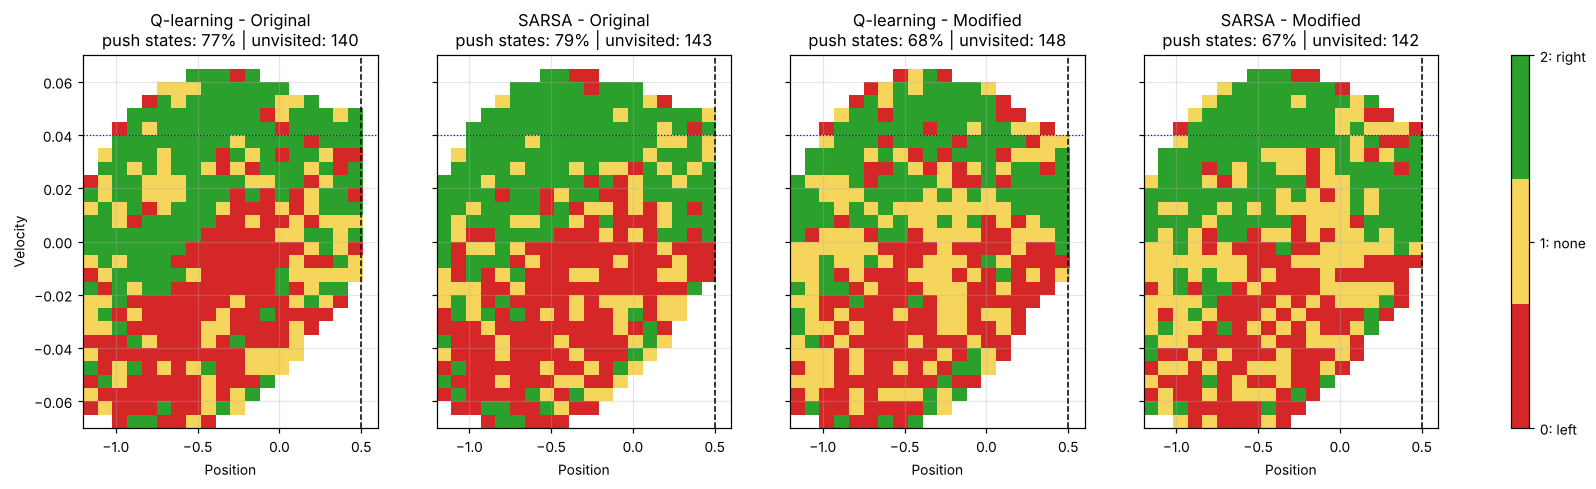

Figure saved to figures/plot5_greedy_policy_maps.png


Agent A,Agent B,Same greedy action
Q-learning - Original,SARSA - Original,0.531
Q-learning - Modified,SARSA - Modified,0.545
Q-learning - Original,Q-learning - Modified,0.476
SARSA - Original,SARSA - Modified,0.533


In [16]:
# Plot 5: greedy-policy maps over the position x velocity grid
cmap = ListedColormap(["#d62728", "#f6d55c", "#2ca02c"])   # 0 = left (red), 1 = no push (yellow), 2 = right (green)
cmap.set_bad("white")                                       # unvisited states are drawn white
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
for ax, (k, (lab, _, _)) in zip(axes, AGENTS.items()):
    Q = RESULTS[k][0]
    greedy = Q.argmax(axis=2).astype(float)       # greedy action per discrete state
    unvisited = np.all(Q == 0, axis=2)            # states never updated keep an all-zero row
    greedy[unvisited] = np.nan                    # masked -> drawn white (no information)
    im = ax.imshow(greedy.T, origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=2,
                   extent=[POS_LOW, POS_HIGH, VEL_LOW, VEL_HIGH])
    ax.axvline(0.5, color="k", lw=1, ls="--")     # flag position
    ax.axhline(GENTLE_VMAX, color="b", lw=0.8, ls=":")  # gentle-arrival velocity threshold
    frac_push = np.mean(greedy[~unvisited] != 1)
    ax.set_title(f"{lab}\npush states: {100*frac_push:.0f}% | unvisited: {unvisited.sum()}")
    ax.set_xlabel("Position")
axes[0].set_ylabel("Velocity")
cb = fig.colorbar(im, ax=axes, ticks=[0, 1, 2], fraction=0.015)
cb.ax.set_yticklabels(["0: left", "1: none", "2: right"])
show_fig(fig, "plot5_greedy_policy_maps")

# Agreement between the greedy policies (fraction of visited states with the same greedy action)
def agreement(k1, k2):
    """Fraction of states visited by both agents where their greedy actions coincide."""
    Q1, Q2 = RESULTS[k1][0], RESULTS[k2][0]
    vis = ~np.all(Q1 == 0, axis=2) & ~np.all(Q2 == 0, axis=2)
    return np.mean(Q1.argmax(2)[vis] == Q2.argmax(2)[vis])
show_table([[AGENTS[k1][0], AGENTS[k2][0], agreement(k1, k2)]
            for k1, k2 in [("q_orig", "s_orig"), ("q_mod", "s_mod"), ("q_orig", "q_mod"), ("s_orig", "s_mod")]],
           ["Agent A", "Agent B", "Same greedy action"], "Greedy-policy agreement on states visited by both agents",
           {"Same greedy action": "{:.3f}"})

**Interpretation — greedy-policy maps.** All four maps show the classic MountainCar structure: push right (green) when the
velocity is positive and left (red) when it is negative, so energy is pumped by swinging. White cells are states that were
never visited (very high |velocity| at the extreme positions).
* The **original** agents push in 77–79% of visited states and the left/right regions are large and fairly clean.
* The **modified** agents push in only 67–68% of states: many cells, mostly near zero velocity and around the bottom of
  the valley where a push changes little, become "do nothing" (yellow). This is the energy penalty at work.
* Near the flag (x → 0.5) with positive velocity the modified maps contain more "do nothing"/left cells just below and
  above the 0.04 line — the agent coasts or brakes to cross the flag slowly, which is what the bonus rewards.
* Q-learning and SARSA agree on only ≈ 53–55% of visited states in each environment: many states have nearly equal
  action values, so small value differences flip the argmax. The maps are noisy for this reason, while the resulting
  behaviour (Table 1) is similar.


In [17]:
# ------------------------------------------------------------------
# Final greedy-policy evaluation (epsilon = 0), 100 test episodes with fixed seeds
# ------------------------------------------------------------------
TEST_SEEDS = list(range(1000, 1100))              # fixed seeds, identical for every agent


def evaluate(Q, modified, seeds=TEST_SEEDS):
    """Run the greedy policy (epsilon = 0) of Q-table Q for one episode per seed and collect statistics."""
    env = make_env(modified)
    rows = []
    for sd in seeds:
        obs, _ = env.reset(seed=sd)               # fixed start state (and fixed sticky RNG in the modified env)
        tie_rng = np.random.default_rng(sd)       # deterministic tie-breaking
        total, steps, pushes, done = 0.0, 0, 0, False
        while not done:
            a = greedy_action(Q[discretize(obs)], tie_rng)   # purely greedy action
            pushes += int(a != 1)
            obs, R, term, trunc, _ = env.step(a)
            total += R; steps += 1; done = term or trunc
        rows.append((total, float(term), float(term and not trunc and obs[1] <= GENTLE_VMAX),
                     steps, pushes, obs[1] if term else np.nan))
    env.close()
    r = np.array(rows)
    return {"mean_reward": r[:, 0].mean(), "std_reward": r[:, 0].std(), "success": r[:, 1].mean(),
            "gentle": r[:, 2].mean(), "length": r[:, 3].mean(), "pushes": r[:, 4].mean(),
            "arr_vel": np.nanmean(r[:, 5]) if np.any(r[:, 1]) else np.nan}


def print_table(title, results):
    """Display one evaluation table (one row per agent) as a bordered table."""
    show_table([[lab, m["mean_reward"], m["std_reward"], m["success"], m["gentle"], m["length"], m["pushes"], m["arr_vel"]]
                for lab, m in results.items()],
               ["Agent", "Mean reward", "Std reward", "Success rate", "Gentle-arrival rate", "Mean episode length",
                "Pushes / episode", "Mean arrival v"], title,
               {"Mean reward": "{:.2f}", "Std reward": "{:.1f}", "Success rate": "{:.2f}", "Gentle-arrival rate": "{:.2f}",
                "Mean episode length": "{:.1f}", "Pushes / episode": "{:.1f}", "Mean arrival v": "{:.4f}"})


# Main table: each agent evaluated in the environment it was trained on (rewards are in that env's units)
EVAL = {AGENTS[k][0]: evaluate(RESULTS[k][0], modified=k.endswith("mod")) for k in AGENTS}
print_table("Table 1 - Greedy policies in their own training environment (100 fixed-seed test episodes)", EVAL)

# Additional robustness table: ALL agents evaluated on the sticky-actuator env with the modified reward,
# so the four numbers are directly comparable (transfer of the original-env agents to sticky actuators).
EVAL_X = {AGENTS[k][0]: evaluate(RESULTS[k][0], modified=True) for k in AGENTS}
print_table("Table 2 - All greedy policies evaluated on the MODIFIED environment (same 100 seeds)", EVAL_X)

Agent,Mean reward,Std reward,Success rate,Gentle-arrival rate,Mean episode length,Pushes / episode,Mean arrival v
Q-learning - Original,-131.57,20.8,1.00,0.76,131.6,108.9,0.0289
SARSA - Original,-158.36,27.9,1.00,0.99,158.4,133.2,0.0296
Q-learning - Modified,-170.93,15.0,1.00,1.00,170.2,103.8,0.0299
SARSA - Modified,-150.02,16.2,0.98,0.98,149.5,100.5,0.0330


Agent,Mean reward,Std reward,Success rate,Gentle-arrival rate,Mean episode length,Pushes / episode,Mean arrival v
Q-learning - Original,-143.78,33.1,0.97,0.74,135.9,113.4,0.0299
SARSA - Original,-156.73,32.0,0.99,0.96,150.3,128.2,0.0290
Q-learning - Modified,-170.93,15.0,1.00,1.00,170.2,103.8,0.0299
SARSA - Modified,-150.02,16.2,0.98,0.98,149.5,100.5,0.0330


**Final greedy evaluation (ε = 0, 100 fixed test seeds).**
* *Table 1* (each agent in its own environment): every agent reaches the flag in 98–100% of test episodes. In the
  original environment Q-learning is faster (131.6 vs 158.4 steps, reward −131.6 vs −158.4) but only 76% of its arrivals
  are gentle (not rewarded there). In the modified environment both agents arrive gently on essentially every success
  (1.00 and 0.98) with ≈ 100–104 pushes per episode; for this seed **SARSA obtains the higher mean reward (−150.0 vs
  −170.9)** with a shorter episode (149.5 vs 170.2 steps).
* *Table 2* (all four agents tested on the modified environment): the agents trained without the sticky actuator still
  succeed, but the original Q-learning policy loses its gentle arrivals (0.74) and both use ≈ 113–128 pushes. Its
  mean reward is nevertheless competitive (−143.8) because it reaches the flag ~35 steps earlier — showing that the
  modified-environment agents have not found the reward-optimal trade-off between speed and gentleness (see the
  limitation in part (e)).


### Additional visuals — greedy trajectories and arrival-speed distribution

To see *how* the learnt policies drive the car, the greedy policy of each agent is rolled out from the first five test seeds and drawn in the (position, velocity) plane, and the velocity at the flag is collected over all 100 test episodes.

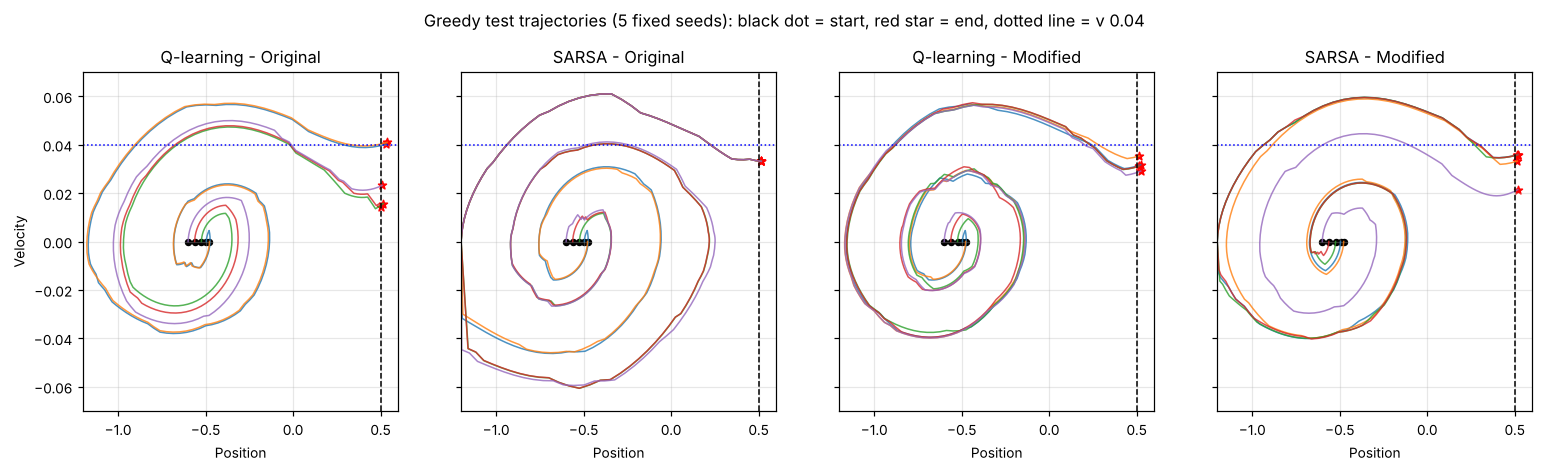

Figure saved to figures/greedy_trajectories.png


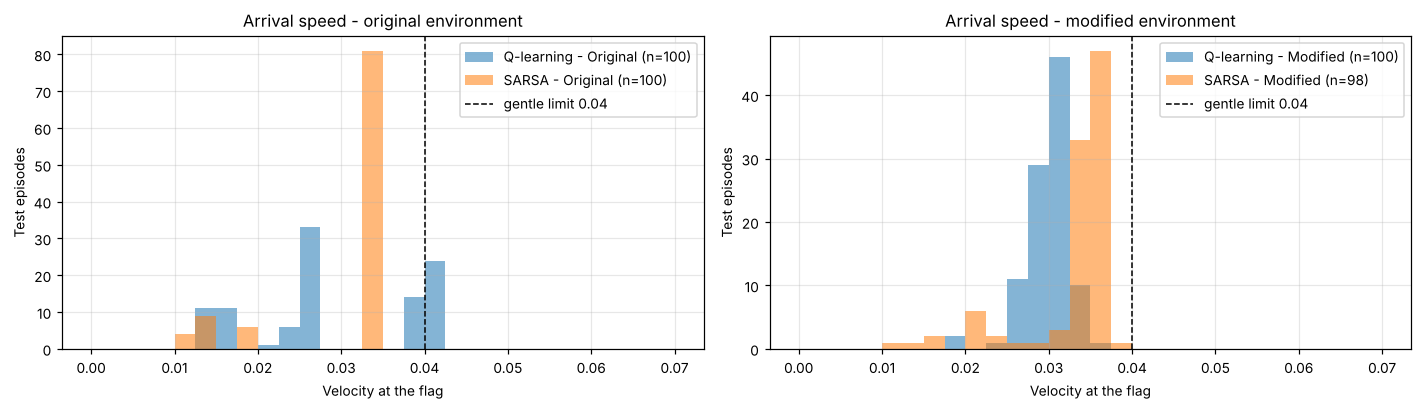

Figure saved to figures/arrival_speed_histogram.png


In [18]:
# ------------------------------------------------------------------
# Additional visuals: greedy trajectories in phase space and arrival-speed distribution
# ------------------------------------------------------------------
def rollout(Q, modified, seed):
    """Run one greedy episode and return the visited positions, velocities and selected actions."""
    env = make_env(modified)
    obs, _ = env.reset(seed=seed)
    tie_rng = np.random.default_rng(seed)
    xs, vs, acts, done = [obs[0]], [obs[1]], [], False
    while not done:
        a = greedy_action(Q[discretize(obs)], tie_rng)   # greedy action, epsilon = 0
        obs, _, term, trunc, _ = env.step(a)
        xs.append(obs[0]); vs.append(obs[1]); acts.append(a); done = term or trunc
    env.close()
    return np.array(xs), np.array(vs), np.array(acts)


# Figure A: five test trajectories per agent in the (position, velocity) plane
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, (k, (lab, col, _)) in zip(axes, AGENTS.items()):
    for sd in TEST_SEEDS[:5]:
        xs, vs, acts = rollout(RESULTS[k][0], k.endswith("mod"), sd)
        ax.plot(xs, vs, lw=1, alpha=0.8)                     # path of the car
        ax.scatter(xs[0], vs[0], s=15, c="k")                # start point
        ax.scatter(xs[-1], vs[-1], s=30, marker="*", c="r")  # final point
    ax.axvline(0.5, color="k", ls="--", lw=1); ax.axhline(GENTLE_VMAX, color="b", ls=":", lw=1)
    ax.set_xlim(POS_LOW, POS_HIGH); ax.set_ylim(VEL_LOW, VEL_HIGH)
    ax.set_title(lab); ax.set_xlabel("Position")
axes[0].set_ylabel("Velocity")
fig.suptitle("Greedy test trajectories (5 fixed seeds): black dot = start, red star = end, dotted line = v 0.04", y=1.02)
show_fig(fig, "greedy_trajectories")

# Figure B: distribution of arrival velocity over the 100 test episodes
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bins = np.linspace(0.0, 0.07, 29)                    # same 0.0025-wide bins for all agents
for idx, keys in enumerate([("q_orig", "s_orig"), ("q_mod", "s_mod")]):
    for k in keys:
        lab, col, _ = AGENTS[k]
        v_end = []
        for sd in TEST_SEEDS:
            xs, vs, _ = rollout(RESULTS[k][0], k.endswith("mod"), sd)
            if xs[-1] >= 0.5:                        # keep only successful episodes
                v_end.append(vs[-1])
        axes[idx].hist(v_end, bins=bins, alpha=0.55, color=col, label=f"{lab} (n={len(v_end)})")
    axes[idx].axvline(GENTLE_VMAX, color="k", ls="--", lw=1, label="gentle limit 0.04")
    axes[idx].set_xlabel("Velocity at the flag"); axes[idx].set_ylabel("Test episodes"); axes[idx].legend()
axes[0].set_title("Arrival speed - original environment"); axes[1].set_title("Arrival speed - modified environment")
plt.tight_layout(); show_fig(fig, "arrival_speed_histogram")

**Interpretation — trajectories and arrival speed.**
* *Trajectories:* every agent builds energy by swinging — the paths spiral outwards from the valley floor (≈ −0.5) until the car can climb past x = 0.5. The original agents swing harder: SARSA-original reaches |v| ≈ 0.06 on the backswing and hits the left wall, and some Q-learning-original runs cross the flag at v ≈ 0.041, just above the gentle limit. Both modified agents bend their paths downwards just before the flag (coasting / braking), so every run ends below the dotted v = 0.04 line.
* *Arrival speed:* in the original environment, where slow arrival earns nothing, the arrival speeds are scattered between 0.01 and 0.043, and about a quarter of Q-learning's arrivals exceed 0.04. In the modified environment all arrivals sit in a tight band at 0.02–0.04 with none above the limit — the agents learnt to arrive "just gently enough", which earns the bonus without wasting extra steps.


### Supplementary: seed robustness (modified environment)

A single seed is a known weakness of this kind of comparison (see part (e)). The modified-environment experiment is
therefore repeated with three additional seeds under exactly the same settings, and each greedy policy is tested on
the same 100 fixed test seeds.


In [19]:
# ------------------------------------------------------------------
# Supplementary robustness check: repeat the modified-environment comparison with extra seeds
# (addresses the single-seed limitation discussed in part (e); set RUN_EXTRA_SEEDS=False to skip)
# ------------------------------------------------------------------
RUN_EXTRA_SEEDS = True
EXTRA_SEEDS = [101, 202, 303]                     # additional, independent seeds

if RUN_EXTRA_SEEDS:
    seed_rows = []
    for sd in [SEED] + EXTRA_SEEDS:
        for algo in ["qlearning", "sarsa"]:
            if sd == SEED:                        # reuse the main runs for the main seed
                Q = RESULTS["q_mod" if algo == "qlearning" else "s_mod"][0]
                st = RESULTS["q_mod" if algo == "qlearning" else "s_mod"][1]
            else:
                Q, st = train_agent(algo, modified=True, seed=sd, verbose=False)
            m = evaluate(Q, modified=True)
            seed_rows.append((sd, algo, m["mean_reward"], m["success"], m["gentle"], m["pushes"],
                              st["avg_maxq"][EPS_DECAY_EPS:].mean()))
            print(f"[{datetime.datetime.now():%H:%M:%S}] seed {sd:3d} | {algo:<9} | test reward {m['mean_reward']:8.2f} | "
                  f"success {m['success']:.2f} | gentle {m['gentle']:.2f} | pushes {m['pushes']:6.1f} | "
                  f"late avg maxQ {seed_rows[-1][-1]:7.2f}")
    sr = np.array([(r[2], r[3], r[4], r[5], r[6]) for r in seed_rows])
    algos = np.array([r[1] for r in seed_rows])
    show_table([[r[0], "Q-learning" if r[1] == "qlearning" else "SARSA", *r[2:]] for r in seed_rows],
               ["Seed", "Algorithm", "Test mean reward", "Success rate", "Gentle rate", "Pushes / episode", "Late avg max Q"],
               "Per-seed results (modified environment, greedy test on 100 fixed seeds)",
               {"Test mean reward": "{:.2f}", "Success rate": "{:.2f}", "Gentle rate": "{:.2f}", "Pushes / episode": "{:.1f}", "Late avg max Q": "{:.2f}"})
    pm = lambda x: f"{x.mean():.2f} ± {x.std():.2f}"   # mean ± std formatter
    show_table([["Q-learning" if a == "qlearning" else "SARSA", pm(sr[algos == a][:, 0]), pm(sr[algos == a][:, 1]),
                 pm(sr[algos == a][:, 2]), f"{sr[algos == a][:, 3].mean():.1f}", pm(sr[algos == a][:, 4])] for a in ["qlearning", "sarsa"]],
               ["Algorithm", "Test mean reward", "Success rate", "Gentle rate", "Pushes / episode", "Late avg max Q"],
               f"Mean ± std over {len(EXTRA_SEEDS) + 1} seeds (modified environment)")
print("\nRun finished at:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

[17:49:38] seed  18 | qlearning | test reward  -170.93 | success 1.00 | gentle 1.00 | pushes  103.8 | late avg maxQ  -26.57


[17:49:38] seed  18 | sarsa     | test reward  -150.02 | success 0.98 | gentle 0.98 | pushes  100.5 | late avg maxQ  -28.79


[17:50:36] seed 101 | qlearning | test reward  -143.69 | success 0.98 | gentle 0.98 | pushes   98.9 | late avg maxQ  -27.21


[17:51:30] seed 101 | sarsa     | test reward  -156.84 | success 1.00 | gentle 1.00 | pushes   98.5 | late avg maxQ  -27.11


[17:52:28] seed 202 | qlearning | test reward  -165.84 | success 0.88 | gentle 0.87 | pushes  106.9 | late avg maxQ  -26.67


[17:53:22] seed 202 | sarsa     | test reward  -164.90 | success 0.92 | gentle 0.92 | pushes  108.7 | late avg maxQ  -28.41


[17:54:20] seed 303 | qlearning | test reward  -139.97 | success 0.98 | gentle 0.97 | pushes  100.5 | late avg maxQ  -26.84


[17:55:14] seed 303 | sarsa     | test reward  -158.20 | success 0.99 | gentle 0.99 | pushes  100.7 | late avg maxQ  -28.40


Seed,Algorithm,Test mean reward,Success rate,Gentle rate,Pushes / episode,Late avg max Q
18,Q-learning,-170.93,1.00,1.00,103.8,-26.57
18,SARSA,-150.02,0.98,0.98,100.5,-28.79
101,Q-learning,-143.69,0.98,0.98,98.9,-27.21
101,SARSA,-156.84,1.00,1.00,98.5,-27.11
202,Q-learning,-165.84,0.88,0.87,106.9,-26.67
202,SARSA,-164.90,0.92,0.92,108.7,-28.41
303,Q-learning,-139.97,0.98,0.97,100.5,-26.84
303,SARSA,-158.20,0.99,0.99,100.7,-28.40


Algorithm,Test mean reward,Success rate,Gentle rate,Pushes / episode,Late avg max Q
Q-learning,-155.11 ± 13.46,0.96 ± 0.05,0.96 ± 0.05,102.5,-26.82 ± 0.24
SARSA,-157.49 ± 5.28,0.97 ± 0.03,0.97 ± 0.03,102.1,-28.18 ± 0.64



Run finished at: 2026-11-08 17:55:14


**Interpretation — seed robustness.** Over four seeds the two algorithms obtain practically the same mean test reward
in the modified environment (Q-learning −155.1 ± 13.5, SARSA −157.5 ± 5.3), success (0.96 vs 0.97) and push count
(≈ 102). The differences are in **consistency** and **value estimates**: SARSA's result varies about 2.5× less across
seeds, and Q-learning's late-training value estimate is higher than SARSA's (−26.8 vs −28.2) in three of the four seeds.
So the seed-18 advantage of SARSA in Table 1 is partly seed luck, while the lower variance and the value gap are robust.


## (e) Discussion

**1. Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?**
Yes, in the converged phase. In the Q-value plot both environments show a large early gap (exploration effect), but once
ε ≈ 0.01 the original-environment gap shrinks to zero (mean +0.03, sign changes), whereas the modified-environment gap
remains positive throughout (mean +2.2 over episodes 7,500–15,000), and the extra seeds confirm a positive gap in
three of four runs (mean ≈ +1.4). The reason is the target: Q-learning's `max_a′ Q(s′,a′)` assumes the best action
will be carried out at s′, but when the best action differs from the current one it is executed only 80% of the time.
The max therefore over-states what can actually be achieved (an optimistic bias added on top of the usual max-operator
over-estimation from noisy returns). SARSA's target uses the action really selected next and averages over what the
actuator really did, so its estimates stay closer to the achievable return.

**2. Why is the modified environment non-Markovian with respect to the observation, and how does this affect credit
assignment?** The true transition depends on (x, v, a_prev, a): whether the selected action is executed depends on
whether it differs from the previously executed action — a variable the agent cannot see (the observation is only
(x, v)). Two visits to the same (x, v) with the same chosen action can lead to different next states purely because
a_prev differs, so P(s′ | s, a) is not a function of the observation and action alone; the process is a POMDP. For credit
assignment this means: (i) the reward and next state of step t are partly caused by the action chosen at an earlier step
(a stuck actuator repeats an old command), yet the TD update credits the action selected at step t; (ii) a "do nothing"
choice can be followed by a push it did not cause (2,599 such steps in the random-policy test), and a push choice is
penalised even when it was not executed; (iii) the resulting extra variance in the TD targets slows learning and makes
the curves noisier, which is visible as the more jagged modified-environment curves and their late-phase collapses.

**3. Do the penalty and the bonus encourage fewer pushes or a slower, controlled arrival?** Both. *Fewer pushes:* the
push-count plot falls to ≈ 105–110 per episode for the modified agents against ≈ 124–129 for the original agents (push
fraction 0.67–0.70 vs 0.84–0.85), and the policy maps show ~10 percentage points fewer push states, with "do nothing"
filling in where pushing achieves little. *Slower arrival:* in the modified environment gentle arrival happens on
99.5–99.7% of successful episodes (vs 66–72% in the original), and the mean arrival speed drops from 0.033–0.034 to
0.025–0.028; the policy maps show coasting/braking cells around v = 0.04 near the flag. The cost is longer episodes
(e.g. 170 vs 132 steps for Q-learning in the test table), i.e. the agents trade time for energy and bonus.

**4. Which algorithm performs better under sticky actuators, and is this consistent with theory?** On seed 18 SARSA is
better in the modified environment (test reward −150.0 vs −170.9, fewer pushes, earlier learning), but over four seeds
the mean rewards are statistically indistinguishable (−157.5 ± 5.3 vs −155.1 ± 13.5). SARSA's advantage is reliability:
2.5× lower variance across seeds and value estimates that are not inflated. This is consistent with theory. Q-learning
is off-policy and learns the value of the greedy policy *as if actions were executed reliably*; with execution noise
that the agent cannot observe, this target is biased and the learnt greedy policy can be "risky". SARSA is on-policy:
it learns the value of what actually happens when its policy is run, including both ε-exploration and actuator
stickiness, which gives more conservative, stable values (the same mechanism as in the Cliff-Walking example). With
ε → 0.01 the two targets differ only through the stuck actions, which is why the performance gap is modest while the
value gap is clear.

**5. Limitation and improvement.** *Limitation:* the experiment uses a coarse 20 × 28 tabular discretisation and a
small number of seeds (one for the main plots). The coarse grid aliases states (adding further partial observability),
gives noisy policy maps (only ≈ 53% Q-learning/SARSA agreement) and, as Table 2 shows, the modified agents do not yet
find the best speed-vs-gentleness trade-off; a single seed cannot separate algorithm effects from luck (the seed-18 SARSA
advantage shrinks when averaged). *Improvement:* run ≥ 10 seeds and report confidence intervals, and give the agent the
missing state by augmenting the observation with the last *selected* action (which the agent itself knows — it is a
good proxy for a_prev) or use tile coding / a finer grid, so that the problem becomes closer to Markovian and value
estimates become less biased. A decaying learning rate would also reduce the late-phase oscillations.
